# Real-Time Anomaly Detection in Financial Transactions
## SecurePay internship project | Isolation Forest vs. Local Outlier Factor

This notebook studies anomaly detection on historical credit card transactions. Suspicious predictions indicate unusual patterns, not confirmed fraud; scores are not calibrated fraud probabilities. The title does not imply a live banking connection or verified real-time inference latency.

### Dataset setup

The current workspace contains **Data/creditcard.csv**, with Class, Time, Amount, and precomputed V1-V28 PCA features. If your copy omits the dataset, supply the compatible CSV at that location. In cell 2, **DATA_PATH = Path("Data/creditcard.csv")** is resolved relative to the kernel working directory. Start the kernel from the project root. Match the uppercase Data directory on case-sensitive systems; the loading cell's lowercase error-message text does not change the configured path.

**CREDIT_CARD_CSV is not supported:** the code does not read this environment variable. Setting it has no effect. Configuring a different path would require an explicit future edit to DATA_PATH; no notebook code is changed for this documentation update. Time supports EDA but is not a model feature; Class is the evaluation label.

### Dependencies and viewing saved results

Use an artifact-compatible Python environment with NumPy, pandas, scikit-learn, Matplotlib, IPython, and joblib. The pinned ML packages are listed in backend/requirements.txt; Matplotlib and notebook tools are additional dependencies. Use a Jupyter-capable editor with ipykernel or JupyterLab. See the [root README setup instructions](README.md#notebook-and-report) for commands. Notebook-only dependencies are not fully pinned.

Saved outputs can be inspected without executing cells. Executing the fitting cells retrains models; cell 12 writes the performance report and cell 13 writes model artifacts. Do not use Run All merely to inspect the submitted results. Any separately approved report regeneration must preserve/reapply the Step 15 runtime and Step 16 contamination clarifications, which are not included in the unchanged report-generation code.

### Evaluation scope

Both detectors fit normal training transactions only. Labels stratify the train/validation/test splits, select thresholds by maximum validation F1, and evaluate held-out test results. Accuracy is not reported because the labels are highly imbalanced. RobustScaler is fitted on training Amount values; existing V1-V28 features remain unchanged.

LOF fits a reproducible 50,000-row normal sample; Isolation Forest fits 170,588 normal rows. Recorded fitting times are not an equal-dataset speed benchmark or inference-latency measurement. The contamination sensitivity experiment varies post-fit score quantiles, not the estimator contamination parameter. See the [performance report](performance_analysis_report.md) and explanatory Markdown before cell 12 for the saved-result qualifications.





In [1]:
from pathlib import Path
import os
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import RobustScaler

RANDOM_STATE = 42
DATA_PATH = Path("Data/creditcard.csv")
LOF_MAX_TRAIN_ROWS = 50_000
PLOT_MAX_PER_CLASS = 5_000
REPORT_PATH = Path('performance_analysis_report.md')

print(f'Dataset: {DATA_PATH.resolve()}')

Dataset: D:\YJ\New folder (2)\New folder (2)\Real-Time Anomaly Detection in Financial Transactions\Data\creditcard.csv


## 1. Load and validate data

Expected target values are `0` (normal) and `1` (fraud). PCA features are discovered by their `V<number>` names. `Time` is inspected during EDA but excluded from model features: its raw scale and periodic meaning differ from the PCA components, and it is not robust-scaled here.

In [2]:
if not DATA_PATH.is_file():
    raise FileNotFoundError("data/creditcard.csv")

df = pd.read_csv(DATA_PATH)
pca_features = [column for column in df.columns if column.startswith('V') and column[1:].isdigit()]
required_columns = {'Class', 'Amount'}
missing_columns = required_columns.difference(df.columns)
if missing_columns:
    raise ValueError(f'Missing required columns: {sorted(missing_columns)}')
if not pca_features:
    raise ValueError('No PCA feature columns named V1, V2, ... were found.')
if df['Class'].isna().any() or not set(df['Class'].unique()).issubset({0, 1}):
    raise ValueError('Class must contain non-null binary labels: 0=normal, 1=fraud.')
if df[pca_features + ['Amount']].isna().any().any():
    raise ValueError('Model features contain missing values; handle them explicitly before fitting.')

df['Class'] = df['Class'].astype(int)
FEATURE_COLUMNS = pca_features + ['Amount']
print(f'{len(df):,} rows | {len(pca_features)} PCA features | {df["Class"].sum():,} fraud rows')
display(df.head())
display(df[FEATURE_COLUMNS + ['Class']].describe().T)

284,807 rows | 28 PCA features | 492 fraud rows


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


,count,mean,std,min,25%,50%,75%,max
V1,284807.0,1.175161e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.384974e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.094852e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,1.021879e-15,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.494498e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.620335e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.149614e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.414189e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995
V10,284807.0,2.238554e-15,1.088850,-24.588262,-0.535426,-0.092917,0.453923,23.745136


## 2. Exploratory data analysis

The class chart uses counts and percentages so the rare class remains visible. Amount and Time are plotted on a log-count scale to show their long-tailed distributions. The box plot compares Amount by label.

,transactions,percent
Normal (0),284315,99.827251
Fraud (1),492,0.172749


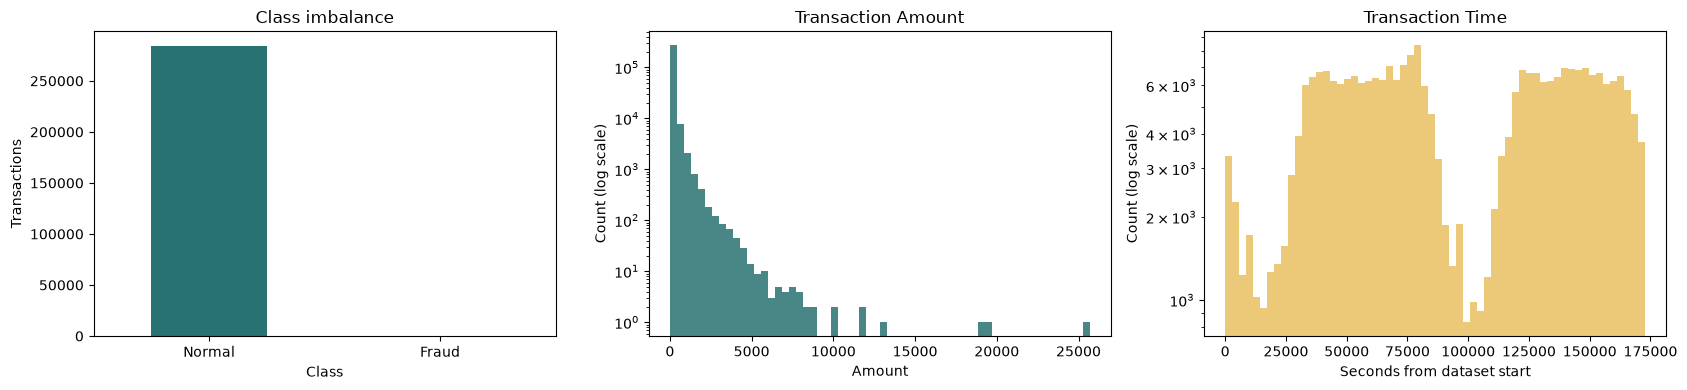

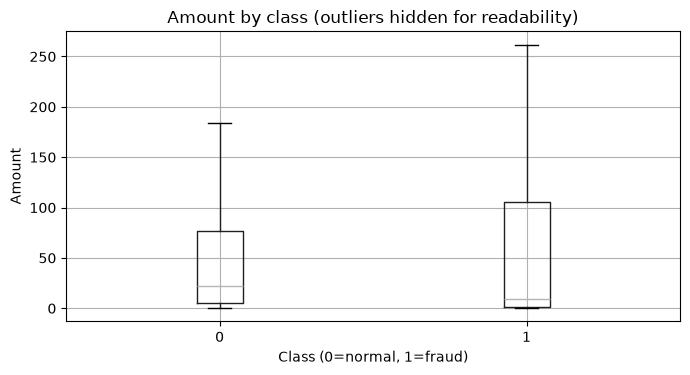

In [18]:
class_counts = df['Class'].value_counts().reindex([0, 1], fill_value=0)
class_summary = pd.DataFrame({
    'transactions': class_counts.to_numpy(),
    'percent': class_counts.to_numpy() / len(df) * 100,
}, index=['Normal (0)', 'Fraud (1)'])
display(class_summary)

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
class_counts.plot(kind='bar', ax=axes[0], color=['#287271', '#e76f51'])
axes[0].set(title='Class imbalance', xlabel='Class', ylabel='Transactions')
axes[0].set_xticklabels(['Normal', 'Fraud'], rotation=0)
for axis in axes[1:]:
    axis.set_yscale('log')
axes[1].hist(df['Amount'], bins=60, color='#287271', alpha=0.85)
axes[1].set(title='Transaction Amount', xlabel='Amount', ylabel='Count (log scale)')
if 'Time' in df.columns:
    axes[2].hist(df['Time'], bins=60, color='#e9c46a', alpha=0.9)
    axes[2].set(title='Transaction Time', xlabel='Seconds from dataset start', ylabel='Count (log scale)')
else:
    axes[2].text(0.5, 0.5, 'No Time column in dataset', ha='center', va='center')
    axes[2].set_axis_off()
plt.tight_layout()
plt.show()

fig, axis = plt.subplots(figsize=(7, 4))
df.boxplot(column='Amount', by='Class', ax=axis, showfliers=False)
axis.set(title='Amount by class (outliers hidden for readability)', xlabel='Class (0=normal, 1=fraud)', ylabel='Amount')
fig.suptitle('')
plt.tight_layout()
plt.show()

## 3. Split first, then scale

Use stratified 60/20/20 train/validation/test splits. Fit `RobustScaler` on the training `Amount` column only and apply that fitted transformation to validation and test. The PCA components are already transformed features and are left unchanged.

In [3]:
train_val_df, test_df = train_test_split(
    df, test_size=0.20, stratify=df['Class'], random_state=RANDOM_STATE
)
train_df, validation_df = train_test_split(
    train_val_df, test_size=0.25, stratify=train_val_df['Class'], random_state=RANDOM_STATE
)

amount_scaler = RobustScaler()
amount_scaler.fit(train_df[['Amount']])

def transform_features(frame):
    transformed = frame[FEATURE_COLUMNS].copy()
    transformed['Amount'] = amount_scaler.transform(frame[['Amount']]).ravel()
    return transformed

X_train = transform_features(train_df)
X_validation = transform_features(validation_df)
X_test = transform_features(test_df)
y_train = train_df['Class'].to_numpy()
y_validation = validation_df['Class'].to_numpy()
y_test = test_df['Class'].to_numpy()

split_summary = pd.DataFrame({
    'rows': [len(train_df), len(validation_df), len(test_df)],
    'fraud': [int(y_train.sum()), int(y_validation.sum()), int(y_test.sum())],
}, index=['train', 'validation', 'test'])
display(split_summary)
if min(y_train.sum(), y_validation.sum(), y_test.sum()) == 0:
    raise ValueError('Each split must contain fraud examples; use a larger dataset or revise split sizes.')

X_train_normal = X_train.loc[y_train == 0]
print(f'Model features: {FEATURE_COLUMNS}')
print(f'Normal-only training rows: {len(X_train_normal):,}')

,rows,fraud
train,170883,295
validation,56962,99
test,56962,98


Model features: ['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount']
Normal-only training rows: 170,588


## 4. Fit unsupervised detectors

Both models see only normal training rows. Raw anomaly scores are normalized so **larger means more anomalous**. LOF uses `novelty=True` because validation and test rows are unseen at fit time; its training subset is randomly capped for practical runtime. `contamination='auto'` avoids embedding a presumed fraud rate into estimator predictions; thresholds are tuned explicitly below.

In [4]:
lof_train = X_train_normal
if len(lof_train) > LOF_MAX_TRAIN_ROWS:
    lof_train = lof_train.sample(n=LOF_MAX_TRAIN_ROWS, random_state=RANDOM_STATE)
print(f'LOF normal-only fit rows: {len(lof_train):,} (cap={LOF_MAX_TRAIN_ROWS:,})')

models = {
    'Isolation Forest': IsolationForest(
        n_estimators=300, contamination='auto', random_state=RANDOM_STATE, n_jobs=-1
    ),
    'Local Outlier Factor': LocalOutlierFactor(
        n_neighbors=20, contamination='auto', novelty=True, n_jobs=-1
    ),
}
fit_data = {'Isolation Forest': X_train_normal, 'Local Outlier Factor': lof_train}
fit_seconds = {}
for name, model in models.items():
    started = time.perf_counter()
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        model.fit(fit_data[name].to_numpy())
    fit_seconds[name] = time.perf_counter() - started
    print(f'{name}: fitted in {fit_seconds[name]:.2f} seconds')

def anomaly_scores(model, features):
    feature_values = np.asarray(features)
    if hasattr(model, 'score_samples'):
        return -model.score_samples(feature_values)
    return -model.decision_function(feature_values)

validation_scores = {name: anomaly_scores(model, X_validation) for name, model in models.items()}
test_scores = {name: anomaly_scores(model, X_test) for name, model in models.items()}
train_normal_scores = {name: anomaly_scores(model, fit_data[name]) for name, model in models.items()}

LOF normal-only fit rows: 50,000 (cap=50,000)
Isolation Forest: fitted in 1.01 seconds
Local Outlier Factor: fitted in 3.98 seconds


## 5. Validation threshold selection and held-out evaluation

Select the score cutoff that maximizes validation F1; labels are not used for fitting the detectors. The contamination estimate is the share of normal-only fit scores beyond that cutoff, not a claim about future fraud prevalence. Final metrics use the untouched test split.

## 6. Visual diagnostics

The precision-recall curves and confusion matrices use held-out test results. PCA is fit on training features and is used only to project test transactions into 2D; detector predictions are made in the original feature space.

## 7. Performance report

The final cell compares both models, recommends the one with higher validation F1, and writes a report containing the resulting test metrics. Review the false-positive burden and validate with a later time period before production; F1 does not encode business-specific fraud and decline costs.

### Runtime measurement provenance

The saved cell 10 fitting output shows Isolation Forest 1.01 s and LOF 3.98 s, while the saved cell 12 comparison/report shows 0.8992 s and 3.5689 s. The report retains the cell 12 snapshot. Cell 12 reads the same `fit_seconds` dictionary populated by cell 10; its separate tree-count experiment uses `fit_time` and does not replace those main comparison values. This discrepancy is not rounding, and the saved evidence cannot distinguish separate executions, changed kernel state, or stale outputs. Execution counts alone do not establish run chronology.

These are model fitting/training-block times, including array conversion and warning-context overhead, not inference latency. Isolation Forest fits 170,588 normal training rows; LOF fits a random 50,000-row normal training sample. This is not an equal-dataset benchmark or a controlled repeated-run comparison. See [Runtime comparison and provenance](performance_analysis_report.md#runtime-comparison-and-provenance) for both snapshots, timing scope, and limitations.

This note documents existing saved results without changing code or outputs. Cell 12 retains its original report-writing template: a future rerun would overwrite the report, so preserve or reapply the provenance clarification and reassess it against any new measurements.

### Contamination sensitivity versus estimator tuning

Cell 12 fits Isolation Forest candidates with n_estimators=100 and 300, both with contamination='auto'. Their saved validation F1 values are 0.190840 and 0.196581. Separately, the sensitivity loop reuses the fitted models and computes np.quantile(train_normal_scores[name], 1 - c) for c=0.005, 0.01, 0.02, 0.05. It evaluates validation score >= cutoff decisions; it does not fit models or change their contamination parameter. This is contamination-based alert-threshold sensitivity, not direct estimator-parameter tuning.

The estimator parameter controls its internal decision boundary; this project instead compares -score_samples against an external threshold. The final Isolation Forest keeps contamination='auto', with its saved score threshold 0.647690607885569 selected by maximum validation F1, not chosen from the four contamination fractions. The reported estimated contamination is the resulting fraction of normal fitting scores flagged by that threshold, not a tuning input or fraud prevalence.

See [Isolation Forest experiments and contamination terminology](performance_analysis_report.md#isolation-forest-experiments-and-contamination-terminology) for saved results, definitions, and limitations. A direct numeric estimator-parameter sweep remains unperformed; if explicitly required by the internship rubric, it needs a separately approved experiment. No such experiment is run here. Preserve or reapply this clarification if the unchanged cell 12 report-writing template is rerun.


,Validation F1 (threshold selection),Test precision,Test recall,Test F1,Test alert rate,Fit seconds,Selected anomaly-score threshold,Estimated contamination
Isolation Forest,0.1966,0.2180,0.2959,0.2511,0.0023,0.8992,0.6477,0.0020
Local Outlier Factor,0.3399,0.2882,0.5000,0.3657,0.0030,3.5689,3.1168,0.0019



Isolation Forest confusion matrix (rows=true [normal, fraud], columns=predicted [normal, fraud]):


,Predicted normal,Predicted fraud
True normal,56760,104
True fraud,69,29



Local Outlier Factor confusion matrix (rows=true [normal, fraud], columns=predicted [normal, fraud]):


,Predicted normal,Predicted fraud
True normal,56743,121
True fraud,49,49


,fit_seconds,validation_f1,threshold
n_estimators,,,
100,0.344153,0.190840,0.643093
300,0.934069,0.196581,0.647691


validation_precision  \
model                contamination_quantile                         
Isolation Forest     0.005                               0.102639   
                     0.010                               0.081037   
                     0.020                               0.056761   
                     0.050                               0.026807   
Local Outlier Factor 0.005                               0.176966   
                     0.010                               0.103989   
                     0.020                               0.053110   
                     0.050                               0.022403   

                                             validation_recall  validation_f1  \
model                contamination_quantile                                     
Isolation Forest     0.005                            0.353535       0.159091   
                     0.010                            0.505051       0.139665   
                     0.020                            0.686869       0.104857   
                     0.050                            0.797980       0.051871   
Local Outlier Factor 0.005                            0.636364       0.276923   
                     0.010                            0.737374       0.182272   
                     0.020                            0.767677       0.099346   
                     0.050                            0.808081       0.043597   

                                             validation_alert_rate  
model                contamination_quantile                         
Isolation Forest     0.005                                0.005986  
                     0.010                                0.010832  
                     0.020                                0.021032  
                     0.050                                0.051736  
Local Outlier Factor 0.005                                0.006250  
                     0.010                                0.012324  
                     0.020                                0.025122  
                     0.050                                0.062691

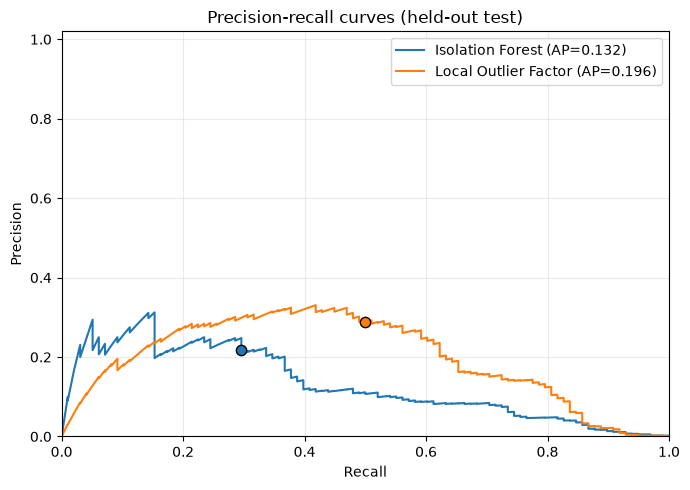

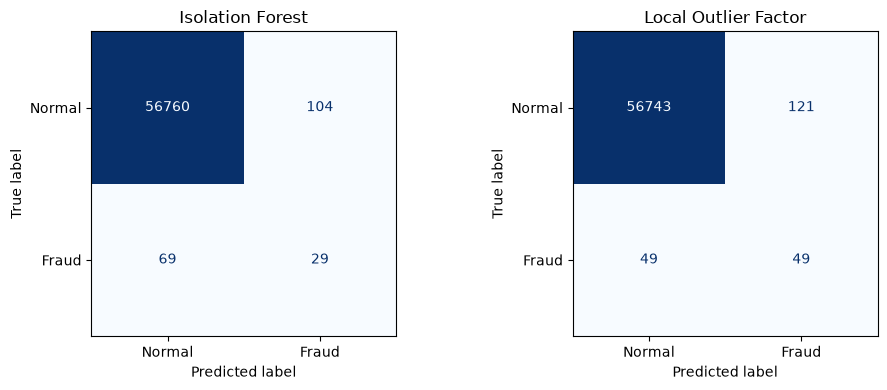

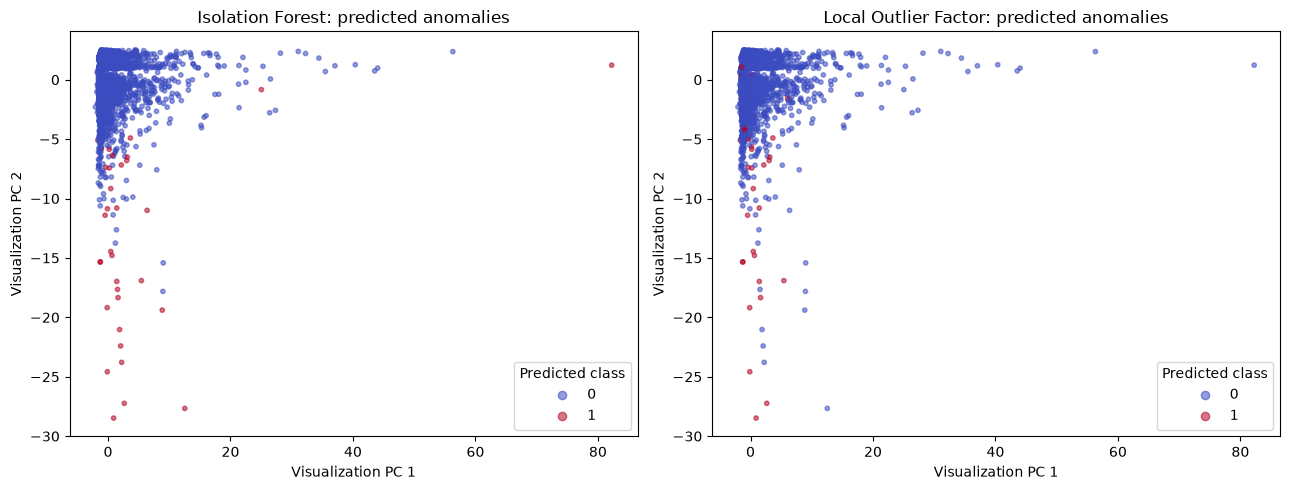

2D PCA explained variance: 40.7%
# SecurePay Anomaly Detection: Performance Analysis

## Evaluation setup

- Dataset: `data\creditcard.csv` (284,807 transactions; 492 fraud labels).
- Features: 29 (V1, V2, V3, V4, V5, V6, V7, V8, V9, V10, V11, V12, V13, V14, V15, V16, V17, V18, V19, V20, V21, V22, V23, V24, V25, V26, V27, V28, Amount). Amount scaled with `RobustScaler` fitted on training data; PCA features unchanged.
- Split: 60% train / 20% validation / 20% test, stratified by class. Models fit only to normal training transactions.
- Threshold: selected by maximum validation F1; final metrics below are from held-out test data.

## Model comparison

                      Validation F1 (threshold selection)  Test precision  Test recall  Test F1  Test alert rate  Fit seconds  Selected anomaly-score threshold  Estimated contamination
Isolation Forest                                   0.1966          0.2180       0.2959   0.2511           0.0023       0.8992                            0.64

In [21]:
def select_f1_threshold(y_true, scores):
    precision, recall, thresholds = precision_recall_curve(y_true, scores)
    if len(thresholds) == 0:
        raise ValueError('Cannot tune a threshold: validation scores have no candidate thresholds.')
    f1_values = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-12)
    best_index = int(np.nanargmax(f1_values))
    return float(thresholds[best_index]), float(f1_values[best_index])


def evaluate_at_threshold(y_true, scores, threshold):
    predictions = (scores >= threshold).astype(int)
    return {
        'precision': precision_score(y_true, predictions, zero_division=0),
        'recall': recall_score(y_true, predictions, zero_division=0),
        'f1': f1_score(y_true, predictions, zero_division=0),
        'alert_rate': float(predictions.mean()),
        'confusion_matrix': confusion_matrix(y_true, predictions, labels=[0, 1]),
        'predictions': predictions,
    }

thresholds = {}
validation_f1 = {}
recommended_contamination = {}
test_results = {}
for name, model in models.items():
    threshold, best_f1 = select_f1_threshold(y_validation, validation_scores[name])
    thresholds[name] = threshold
    validation_f1[name] = best_f1
    recommended_contamination[name] = float(np.mean(train_normal_scores[name] >= threshold))
    test_results[name] = evaluate_at_threshold(y_test, test_scores[name], threshold)

comparison = pd.DataFrame({
    name: {
        'Validation F1 (threshold selection)': validation_f1[name],
        'Test precision': test_results[name]['precision'],
        'Test recall': test_results[name]['recall'],
        'Test F1': test_results[name]['f1'],
        'Test alert rate': test_results[name]['alert_rate'],
        'Fit seconds': fit_seconds[name],
        'Selected anomaly-score threshold': thresholds[name],
        'Estimated contamination': recommended_contamination[name],
    }
    for name in models
}).T
display(comparison.round(4))

for name in models:
    print(f'\n{name} confusion matrix (rows=true [normal, fraud], columns=predicted [normal, fraud]):')
    display(pd.DataFrame(
        test_results[name]['confusion_matrix'],
        index=['True normal', 'True fraud'],
        columns=['Predicted normal', 'Predicted fraud'],
    ))

# Compare IF tree counts; all candidates remain trained on normal rows only.
isolation_forest_grid = []
for tree_count in [100, 300]:
    candidate = IsolationForest(
        n_estimators=tree_count, contamination='auto', random_state=RANDOM_STATE, n_jobs=-1
    )
    started = time.perf_counter()
    candidate.fit(X_train_normal.to_numpy())
    fit_time = time.perf_counter() - started
    candidate_validation_scores = anomaly_scores(candidate, X_validation)
    candidate_threshold, candidate_f1 = select_f1_threshold(y_validation, candidate_validation_scores)
    isolation_forest_grid.append({
        'n_estimators': tree_count,
        'fit_seconds': fit_time,
        'validation_f1': candidate_f1,
        'threshold': candidate_threshold,
    })
display(pd.DataFrame(isolation_forest_grid).set_index('n_estimators'))

contamination_rows = []
for name in models:
    for contamination in [0.005, 0.01, 0.02, 0.05]:
        candidate_threshold = float(np.quantile(train_normal_scores[name], 1 - contamination))
        result = evaluate_at_threshold(y_validation, validation_scores[name], candidate_threshold)
        contamination_rows.append({
            'model': name,
            'contamination_quantile': contamination,
            'validation_precision': result['precision'],
            'validation_recall': result['recall'],
            'validation_f1': result['f1'],
            'validation_alert_rate': result['alert_rate'],
        })
display(pd.DataFrame(contamination_rows).set_index(['model', 'contamination_quantile']))

fig, axis = plt.subplots(figsize=(7, 5))
for name in models:
    precision, recall, _ = precision_recall_curve(y_test, test_scores[name])
    average_precision = average_precision_score(y_test, test_scores[name])
    axis.plot(recall, precision, label=f'{name} (AP={average_precision:.3f})')
    result = test_results[name]
    axis.scatter(result['recall'], result['precision'], s=55, edgecolor='black', zorder=3)
axis.set(title='Precision-recall curves (held-out test)', xlabel='Recall', ylabel='Precision', xlim=(0, 1), ylim=(0, 1.02))
axis.grid(alpha=0.25)
axis.legend()
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for axis, name in zip(axes, models):
    ConfusionMatrixDisplay(
        confusion_matrix=test_results[name]['confusion_matrix'],
        display_labels=['Normal', 'Fraud'],
    ).plot(ax=axis, colorbar=False, cmap='Blues', values_format='d')
    axis.set_title(name)
plt.tight_layout()
plt.show()

plot_frames = []
for label, group in test_df.groupby('Class'):
    plot_frames.append(group.sample(n=min(len(group), PLOT_MAX_PER_CLASS), random_state=RANDOM_STATE))
plot_df = pd.concat(plot_frames).sort_index()
plot_positions = test_df.index.get_indexer(plot_df.index)
plot_features = X_test.iloc[plot_positions]
visual_pca = PCA(n_components=2, random_state=RANDOM_STATE)
visual_pca.fit(X_train)
plot_embedding = visual_pca.transform(plot_features)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for axis, name in zip(axes, models):
    sampled_predictions = test_results[name]['predictions'][plot_positions]
    scatter = axis.scatter(
        plot_embedding[:, 0], plot_embedding[:, 1], c=sampled_predictions,
        cmap='coolwarm', alpha=0.55, s=10, vmin=0, vmax=1,
    )
    axis.set(title=f'{name}: predicted anomalies', xlabel='Visualization PC 1', ylabel='Visualization PC 2')
    axis.legend(*scatter.legend_elements(), title='Predicted class')
plt.tight_layout()
plt.show()
print(f'2D PCA explained variance: {visual_pca.explained_variance_ratio_.sum():.1%}')

recommended_model = max(validation_f1, key=validation_f1.get)
recommended_result = test_results[recommended_model]
report = f"""# SecurePay Anomaly Detection: Performance Analysis

## Evaluation setup

- Dataset: `{DATA_PATH}` ({len(df):,} transactions; {int(df['Class'].sum()):,} fraud labels).
- Features: {len(FEATURE_COLUMNS)} ({', '.join(FEATURE_COLUMNS)}). Amount scaled with `RobustScaler` fitted on training data; PCA features unchanged.
- Split: 60% train / 20% validation / 20% test, stratified by class. Models fit only to normal training transactions.
- Threshold: selected by maximum validation F1; final metrics below are from held-out test data.

## Model comparison

{comparison.to_string(float_format=lambda value: f'{value:.4f}')}

## Recommendation

Recommend **{recommended_model}** for the next evaluation stage because it achieved the higher validation F1 ({validation_f1[recommended_model]:.4f}). Its selected anomaly-score threshold is **{thresholds[recommended_model]:.6f}**, with a normal-training-score contamination estimate of **{recommended_contamination[recommended_model]:.2%}**. On held-out test data: precision **{recommended_result['precision']:.4f}**, recall **{recommended_result['recall']:.4f}**, F1 **{recommended_result['f1']:.4f}**, and alert rate **{recommended_result['alert_rate']:.2%}**.

The contamination estimate is a quantile-based operational starting point, not verified fraud prevalence. Validate the rate on a later time period and set the production threshold according to fraud-loss and false-decline costs. This random split is a baseline; a chronological evaluation is recommended before deployment.

## Confusion matrices

Rows are true labels (normal, fraud); columns are predicted labels (normal, fraud).

- Isolation Forest: `\n{test_results['Isolation Forest']['confusion_matrix']}`
- Local Outlier Factor: `\n{test_results['Local Outlier Factor']['confusion_matrix']}`
"""
REPORT_PATH.write_text(report, encoding='utf-8')
print(report)
print(f'\nSaved generated report to: {REPORT_PATH.resolve()}')

In [5]:
import json
from datetime import datetime, timezone

import joblib
import sklearn

required_state = [
    'models', 'amount_scaler', 'FEATURE_COLUMNS', 'RANDOM_STATE',
    'X_test', 'test_df', 'test_scores', 'X_train', 'y_validation',
    'validation_scores',
]
missing_state = [name for name in required_state if name not in globals()]
if missing_state:
    raise RuntimeError(
        f'Missing notebook state: {missing_state}. Run code cells 2 (imports), 4 (load data), '
        '8 (split and fit scaler), and 10 (fit models and calculate scores), then run this cell. '
        'Thresholds are selected here using validation data only.'
    )

if list(X_test.columns) != list(FEATURE_COLUMNS):
    raise ValueError('X_test feature order differs from FEATURE_COLUMNS.')


def validation_f1_threshold(y_true, scores):
    precision, recall, candidate_thresholds = precision_recall_curve(y_true, scores)
    if len(candidate_thresholds) == 0:
        raise ValueError('Cannot select a threshold: validation scores have no candidate values.')
    f1_values = (
        2 * precision[:-1] * recall[:-1]
        / (precision[:-1] + recall[:-1] + 1e-12)
    )
    return float(candidate_thresholds[int(np.nanargmax(f1_values))])


selected_thresholds = {}
for model_name in models:
    if 'thresholds' in globals() and model_name in thresholds:
        selected_thresholds[model_name] = float(thresholds[model_name])
    else:
        selected_thresholds[model_name] = validation_f1_threshold(
            y_validation, validation_scores[model_name]
        )

artifact_dir = Path('models')
artifact_dir.mkdir(parents=True, exist_ok=True)
artifact_paths = {
    'Isolation Forest': artifact_dir / 'isolation_forest.joblib',
    'Local Outlier Factor': artifact_dir / 'lof_model.joblib',
    'Amount scaler': artifact_dir / 'amount_scaler.joblib',
}
joblib.dump(models['Isolation Forest'], artifact_paths['Isolation Forest'])
joblib.dump(models['Local Outlier Factor'], artifact_paths['Local Outlier Factor'])
joblib.dump(amount_scaler, artifact_paths['Amount scaler'])

metadata = {
    'model_names': {
        name: type(models[name]).__name__
        for name in ('Isolation Forest', 'Local Outlier Factor')
    },
    'artifact_files': {
        name: path.name for name, path in artifact_paths.items()
    },
    'feature_names_in_order': list(FEATURE_COLUMNS),
    'thresholds': selected_thresholds,
    'threshold_selection': 'Maximum validation F1 using validation labels and anomaly scores; test labels are not used for threshold selection.',
    'random_state': int(RANDOM_STATE),
    'scikit_learn_version': sklearn.__version__,
    'artifact_generated_at_utc': datetime.now(timezone.utc).isoformat(),
    'preprocessing': {
        'scaler': 'sklearn.preprocessing.RobustScaler',
        'scaler_artifact': artifact_paths['Amount scaler'].name,
        'scaled_features': ['Amount'],
        'unscaled_features': [name for name in FEATURE_COLUMNS if name != 'Amount'],
        'scaler_fit_data': 'Training split Amount column, before normal-only model filtering.',
        'model_feature_order': list(FEATURE_COLUMNS),
        'anomaly_score_direction': 'Higher scores are more anomalous; score = -score_samples(features).',
        'prediction_rule': 'Flag as anomaly when anomaly_score >= the saved model threshold.',
    },
}
metadata_path = artifact_dir / 'metadata.json'
metadata_path.write_text(json.dumps(metadata, indent=2), encoding='utf-8')

loaded_models = {
    'Isolation Forest': joblib.load(artifact_paths['Isolation Forest']),
    'Local Outlier Factor': joblib.load(artifact_paths['Local Outlier Factor']),
}
loaded_scaler = joblib.load(artifact_paths['Amount scaler'])
loaded_metadata = json.loads(metadata_path.read_text(encoding='utf-8'))

assert loaded_metadata['feature_names_in_order'] == list(FEATURE_COLUMNS)
assert loaded_metadata['random_state'] == int(RANDOM_STATE)
assert loaded_metadata['scikit_learn_version'] == sklearn.__version__
for model_name in models:
    assert np.isclose(
        loaded_metadata['thresholds'][model_name], selected_thresholds[model_name],
        rtol=0.0, atol=1e-12,
    )
    assert loaded_models[model_name].n_features_in_ == len(FEATURE_COLUMNS)

sample_count = min(256, len(X_test))
if sample_count == 0:
    raise ValueError('X_test is empty; cannot verify artifact predictions.')
X_test_sample = X_test.iloc[:sample_count]
raw_test_sample = test_df.loc[X_test_sample.index, FEATURE_COLUMNS].copy()
scaled_test_sample = raw_test_sample.copy()
scaled_test_sample['Amount'] = loaded_scaler.transform(raw_test_sample[['Amount']]).ravel()
np.testing.assert_allclose(
    scaled_test_sample[FEATURE_COLUMNS].to_numpy(),
    X_test_sample[FEATURE_COLUMNS].to_numpy(),
    rtol=1e-7,
    atol=1e-10,
)

verification_rows = []
for model_name, loaded_model in loaded_models.items():
    original_scores = np.asarray(test_scores[model_name][:sample_count])
    reloaded_scores = anomaly_scores(loaded_model, X_test_sample)
    np.testing.assert_allclose(reloaded_scores, original_scores, rtol=1e-7, atol=1e-10)

    saved_threshold = float(loaded_metadata['thresholds'][model_name])
    reloaded_predictions = (reloaded_scores >= saved_threshold).astype(int)
    notebook_predictions = (original_scores >= selected_thresholds[model_name]).astype(int)
    np.testing.assert_array_equal(reloaded_predictions, notebook_predictions)
    if 'test_results' in globals():
        np.testing.assert_array_equal(
            reloaded_predictions,
            test_results[model_name]['predictions'][:sample_count],
        )

    verification_rows.append({
        'model': model_name,
        'sample_rows': sample_count,
        'max_abs_score_difference': float(np.max(np.abs(reloaded_scores - original_scores))),
        'threshold': saved_threshold,
        'predictions_match': True,
    })

display(pd.DataFrame(verification_rows).set_index('model'))
print(f'Artifacts saved and verified in: {artifact_dir.resolve()}')
print(f'Metadata: {metadata_path.resolve()}')

,sample_rows,max_abs_score_difference,threshold,predictions_match
model,,,,
Isolation Forest,256,0.0,0.647691,True
Local Outlier Factor,256,0.0,3.116836,True


Artifacts saved and verified in: D:\YJ\New folder (2)\New folder (2)\Real-Time Anomaly Detection in Financial Transactions\models
Metadata: D:\YJ\New folder (2)\New folder (2)\Real-Time Anomaly Detection in Financial Transactions\models\metadata.json
